In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [57]:
pd.set_option('display.precision',3)
plt.rcParams['font.family']='Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['axes.grid'] = True
sns.set_theme(style='whitegrid', font='Malgun Gothic')

In [3]:
CM = '23_cmapss_fd001_sample.csv'
CM_unit1 = '23_cmapss_unit1_timestamp.csv'
PL = '23_전기Panel.csv'

In [4]:
df = pd.read_csv(CM_unit1)

In [5]:
df['timestamp'] = pd.to_datetime(
    df['timestamp'],
    format='%Y-%m-%d %H:%M:%S',
    errors='coerce'  # 결측치나 오류가 있다면 삭?제 함
    )

df = df.set_index('timestamp').sort_index()

In [6]:
df.head()

,unit_number,time_cycles,sensor_2,sensor_3,sensor_4,sensor_7,sensor_11,sensor_15
timestamp,,,,,,,,
2024-01-01 00:00:00,1,1,642.15,1591.29,1393.17,554.14,47.31,8.47
2024-01-01 01:00:00,1,2,641.96,1582.53,1401.36,554.46,48.04,8.49
2024-01-01 02:00:00,1,3,642.20,1591.05,1403.09,553.11,47.71,8.45
2024-01-01 03:00:00,1,4,642.46,1592.33,1416.91,554.68,47.33,8.47
2024-01-01 04:00:00,1,5,641.94,1584.72,1408.58,554.19,47.69,8.44


In [7]:
# ex 1

# 시계열 데이터 분할해보기

In [9]:
len(df.loc['2024-01-02'])

24

In [10]:
len(df.loc['2024-01-03':'2024-01-05'])

72

In [11]:
# ex 2

# 리샘플림 집계와 시간이동 통계

In [12]:
day = df['sensor_11'].resample('D').mean()

h6 = df['sensor_11'].resample('6h').mean()

In [15]:
len(day)

8

In [16]:
len(h6)

32

In [17]:
day_ma = day.rolling(3).mean()

In [18]:
day_ma

timestamp
2024-01-01       NaN
2024-01-02       NaN
2024-01-03    47.648
2024-01-04    47.810
2024-01-05    48.077
2024-01-06    48.425
2024-01-07    48.798
2024-01-08    49.262
Freq: D, Name: sensor_11, dtype: float64

In [19]:
# ex 3
 
# 다중센서 정규화/ 비교

In [20]:
df0 = pd.read_csv(CM)

In [21]:
u2 = df0[df0['unit_number'] == 2].copy().reset_index(drop=True)

In [23]:
col = ['sensor_2','sensor_7','sensor_11']

norm = (u2[col] - u2[col].min()) / (u2[col].max() - u2[col].min())

norm.min().to_list()

[0.0, 0.0, 0.0]

In [24]:
norm.max().to_list()

[1.0, 1.0, 1.0]

In [25]:
norm_ma = norm.rolling(10).mean()

In [27]:
norm_ma.isna().sum()

sensor_2     9
sensor_7     9
sensor_11    9
dtype: int64

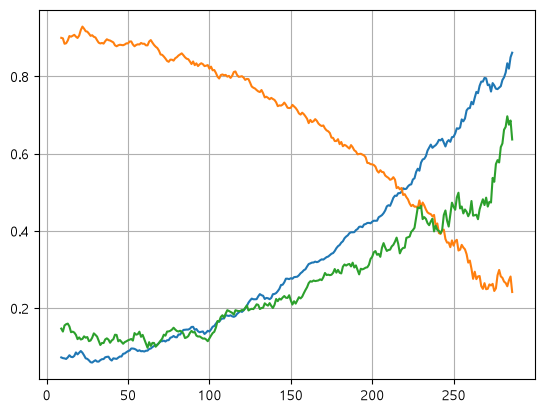

In [32]:
plt.plot(
    norm_ma.index,
    norm_ma.values
)

plt.show()

In [29]:
# ex 4

# 여러 컬럼의 변화 폭 비교

In [33]:
df.columns

Index(['unit_number', 'time_cycles', 'sensor_2', 'sensor_3', 'sensor_4',
       'sensor_7', 'sensor_11', 'sensor_15'],
      dtype='str')

In [35]:
sensors = ['sensor_2', 'sensor_3', 'sensor_4','sensor_7', 'sensor_11', 'sensor_15']

n = (u2[sensors] - u2[sensors].min()) / (u2[sensors].max() - u2[sensors].min())

n_ma = n.rolling(10).mean()

sensor_2 0.072 0.528 0.456
sensor_3 0.171 0.452 0.281
sensor_4 0.266 0.491 0.225
sensor_7 0.901 0.491 -0.41
sensor_11 0.128 0.385 0.257
sensor_15 0.162 0.477 0.315


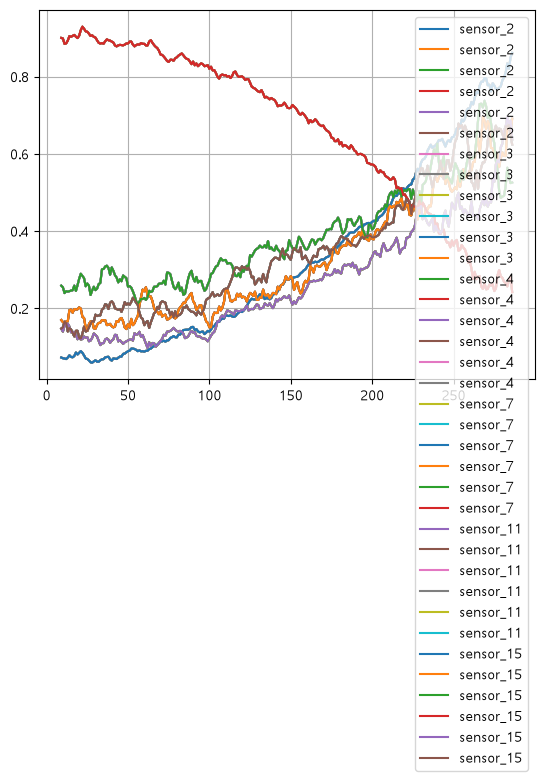

In [44]:
for c in sensors:
    e = n_ma[c].iloc[10:40].mean()
    l = n_ma[c].iloc[150:].mean()

    print(c, round(e,3), round(l,3), round(l - e,3))

    plt.plot(
    n_ma.index,
    n_ma.values,
    label=f'{c}'
)

plt.legend()
plt.show()

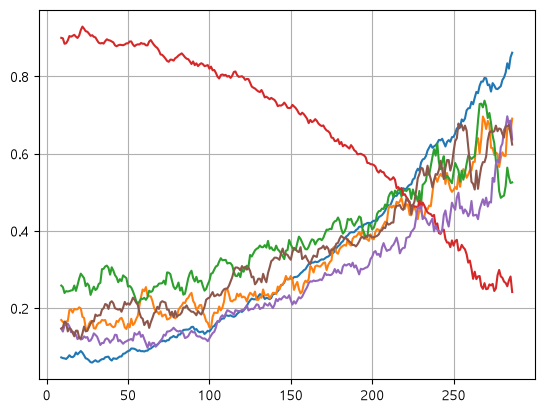

In [46]:
plt.plot(
    n_ma.index,
    n_ma.values,
    # label=f'{}'
)

# plt.legend()
plt.show()

In [ ]:
# ex 4

# AI clean

In [ ]:
result = []

for c in sensors:
    e = n_ma[c].iloc[10:40].mean()
    l = n_ma[c].iloc[150:].mean()

    result.append({
        '센서': c,
        '초기 평균': round(e, 3),
        '후기 평균': round(l, 3),
        '변화량': round(l - e, 3)
    })


result_df = pd.DataFrame(result)


result_df['변화 상태'] = result_df['변화량'].apply(
    lambda x: '증가' if x > 0 else ('감소' if x < 0 else '유지')
)


result_df

,센서,초기 평균,후기 평균,변화량,변화 상태
0,sensor_2,0.072,0.528,0.456,증가
1,sensor_3,0.171,0.452,0.281,증가
2,sensor_4,0.266,0.491,0.225,증가
3,sensor_7,0.901,0.491,-0.410,감소
4,sensor_11,0.128,0.385,0.257,증가
5,sensor_15,0.162,0.477,0.315,증가


In [60]:
# ex 5

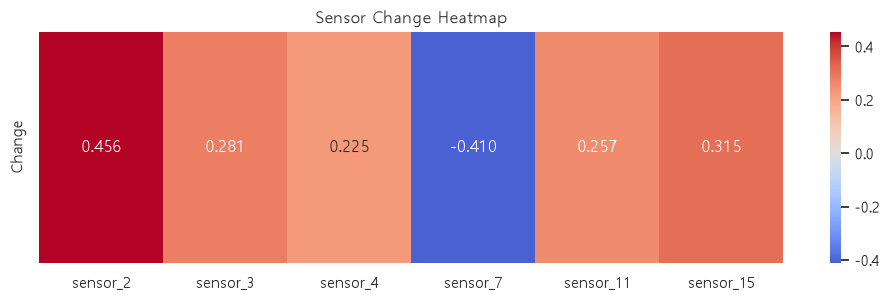

In [59]:

plt.figure(figsize=(12, 3))


sns.heatmap(
    result_df[['변화량']].T,  # 변화량 열을 추출하고 행과 열을 전치
    annot=True,               # 각 셀에 실제 수치 표시
    fmt='.3f',                # 소수점 셋째 자리까지 표시
    cmap='coolwarm',           
    center=0,                 
    xticklabels=result_df['센서'],  
    yticklabels=['Change']    
)


plt.title('Sensor Change Heatmap')

plt.show()

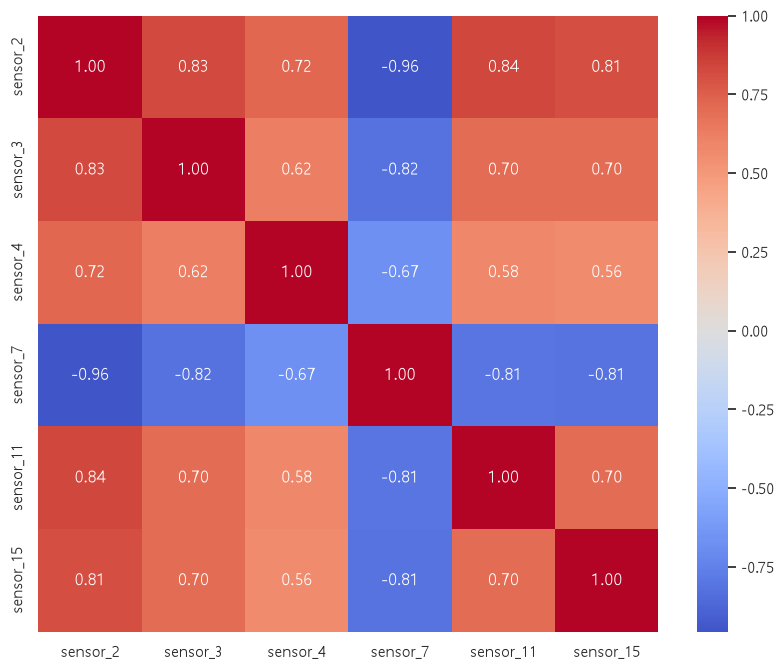

In [ ]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr,          # 상관계수
    annot=True,      
    fmt='.2f',       
    cmap='coolwarm',  
    center=0         
)


plt.show()

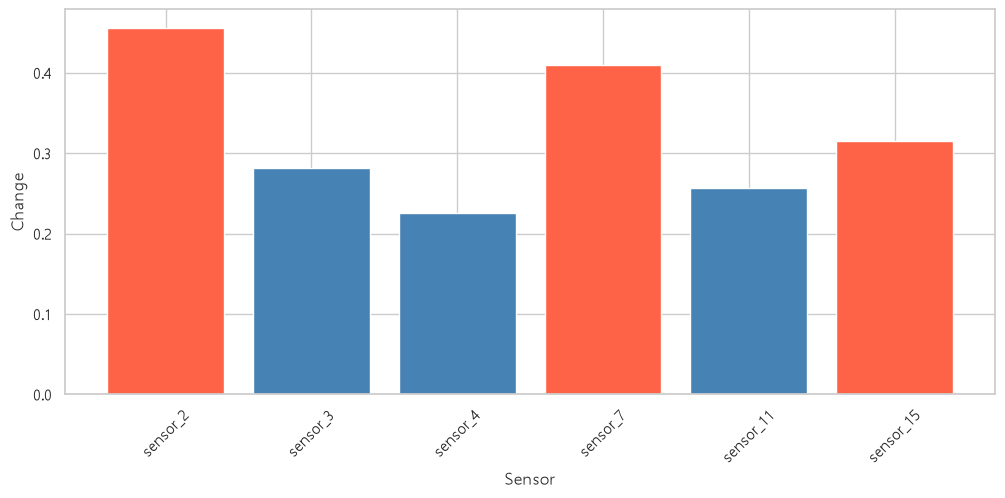

In [114]:

plt.figure(figsize=(12, 5))

# 센서별 변화량을 막대그래프로 표현

# 변화량이 양수면 파란색, 음수면 빨간색

plt.bar(
    result_df['센서'],
    result_df['변화량'].abs(),
    color=['steelblue' if abs(x) <= 0.3 else 'tomato'
           for x in result_df['변화량']]
)

# plt.axhline(0.35, color='yellow', linewidth=1)


plt.xlabel('Sensor')
plt.ylabel('Change')

plt.xticks(rotation=45)


# plt.grid(axis='y', alpha=0.3)

plt.show()

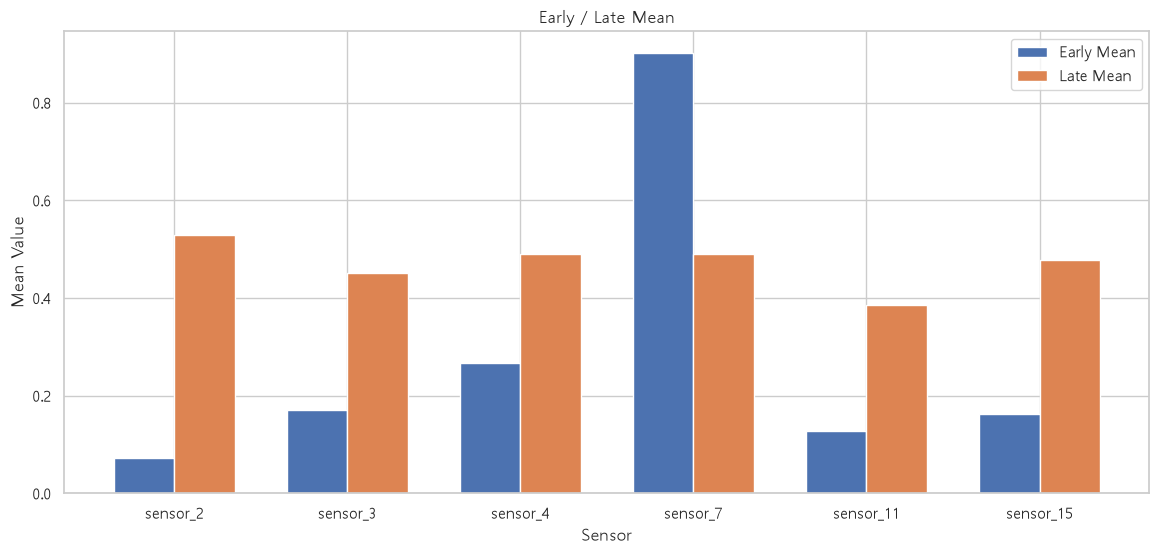

In [119]:
# 센서 개수만큼 X축 위치 생성
x = np.arange(len(result_df))

# 막대그래프 너비 설정
width = 0.35

plt.figure(figsize=(14, 6))


# x - width/2를 사용해 센서별 막대 위치 조정
plt.bar(
    x - width/2,
    result_df['초기 평균'],
    width,
    label='Early Mean'
)


# x + width/2를 사용해 초기 평균과 나란히 배치
plt.bar(
    x + width/2,
    result_df['후기 평균'],
    width,
    label='Late Mean'
)


plt.xticks(x, result_df['센서'])


plt.title('Early / Late Mean')


plt.xlabel('Sensor')
plt.ylabel('Mean Value')

# 범례 표시 (초기, 후기 평균)
plt.legend()

# plt.grid(axis='y', alpha=0.3)

plt.show()

In [ ]:
# ex 6
# 높은 상관의 센서 추출

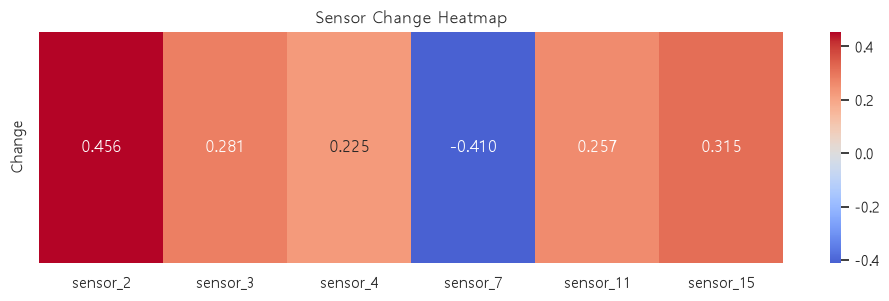

In [ ]:
corr = u2[sensors].corr()

In [ ]:
# pa = corr.where(~np.eye(len(corr), dtype=bool)).unstack().dropna()

# pa = pa[pa.index.map(lambda x: x[0] < x[1])].sort_values()

# pa.index[0], round(pa.iloc[0],3)
# pa.index[-1], round(pa.iloc[-1],3)

In [72]:
pa = corr.where(~np.eye(len(corr), dtype=bool)).unstack().dropna()

pa = pa[pa.index.map(lambda x: x[0] < x[1])].sort_values()

print(pa.index[0], round(pa.iloc[0],3))
print(pa.index[-1], round(pa.iloc[-1],3))

('sensor_2', 'sensor_7') -0.955
('sensor_11', 'sensor_2') 0.839


In [77]:
pa

sensor_2   sensor_7    -0.955
sensor_3   sensor_7    -0.818
sensor_15  sensor_7    -0.812
sensor_11  sensor_7    -0.809
sensor_4   sensor_7    -0.675
sensor_15  sensor_4     0.563
sensor_11  sensor_4     0.577
sensor_3   sensor_4     0.624
sensor_11  sensor_3     0.699
           sensor_15    0.700
sensor_15  sensor_3     0.702
sensor_2   sensor_4     0.719
sensor_15  sensor_2     0.812
sensor_2   sensor_3     0.832
sensor_11  sensor_2     0.839
dtype: float64

In [ ]:
# 상관관계가 가장 낮은 센서 쌍
l_pair = pa.index[0]
l_value = pa.iloc[0]

# 상관관계가 가장 높은 센서 쌍
h_pair = pa.index[-1]
h_value = pa.iloc[-1]

# DataFrame 생성
pa_df = pd.DataFrame([
    {
        '구분': '최저 상관관계',
        '센서 1': l_pair[0],
        '센서 2': l_pair[1],
        '상관계수': round(l_value, 3)
    },
    {
        '구분': '최고 상관관계',
        '센서 1': h_pair[0],
        '센서 2': h_pair[1],
        '상관계수': round(h_value, 3)
    }
])


pa_df


,구분,센서 1,센서 2,상관계수
0,최저 상관관계,sensor_2,sensor_7,-0.955
1,최고 상관관계,sensor_11,sensor_2,0.839


In [80]:
# 행열의 곱샘

In [ ]:
# ex 7
# 종합

In [84]:
u2.info()

<class 'pandas.DataFrame'>
RangeIndex: 287 entries, 0 to 286
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   unit_number  287 non-null    int64  
 1   time_cycles  287 non-null    int64  
 2   sensor_2     287 non-null    float64
 3   sensor_3     287 non-null    float64
 4   sensor_4     287 non-null    float64
 5   sensor_7     287 non-null    float64
 6   sensor_11    287 non-null    float64
 7   sensor_15    287 non-null    float64
dtypes: float64(6), int64(2)
memory usage: 18.1 KB


In [123]:
s = u2['sensor_2']

u2['ma'] = s.rolling(10).mean()
u2['std'] = s.rolling(10).std()

# 잔차계산
resid = s - u2['ma']

# 변화점 
u2['chg'] = resid.abs() > 2 * resid.std()


# 변동성 초/후반 비교

print('변동성  초반 /후반 :', 
        round(u2['std'].iloc[10:71].mean(), 3),'/',
        round(u2['std'].iloc[210:].mean(), 3))  

print('변동률: 초반 /후반 --',
        round(u2['std'].iloc[10:71].mean(), 3)* 100,'%','/',
        round(u2['std'].iloc[210:].mean(), 3)* 100,'%')

# 총 변화점 개수
print('변화점 :', int(u2['chg'].sum()),'개')          

for lo, hi in ((0, 72), (72, 144), (144, 216), (216, 288)):

    seg = u2[(u2.time_cycles > lo) & (u2.time_cycles <= hi)]

    print(
        f'{lo}~{hi}: '
        f'변동성 {seg["std"].mean():.3f}, '
        f'변화점 {int(seg["chg"].sum())}개'
    )

변동성  초반 /후반 : 0.301 / 0.697
변동률: 초반 /후반 -- 30.099999999999998 % / 69.69999999999999 %
변화점 : 19 개
0~72: 변동성 0.304, 변화점 0개
72~144: 변동성 0.311, 변화점 1개
144~216: 변동성 0.295, 변화점 0개
216~288: 변동성 0.723, 변화점 18개


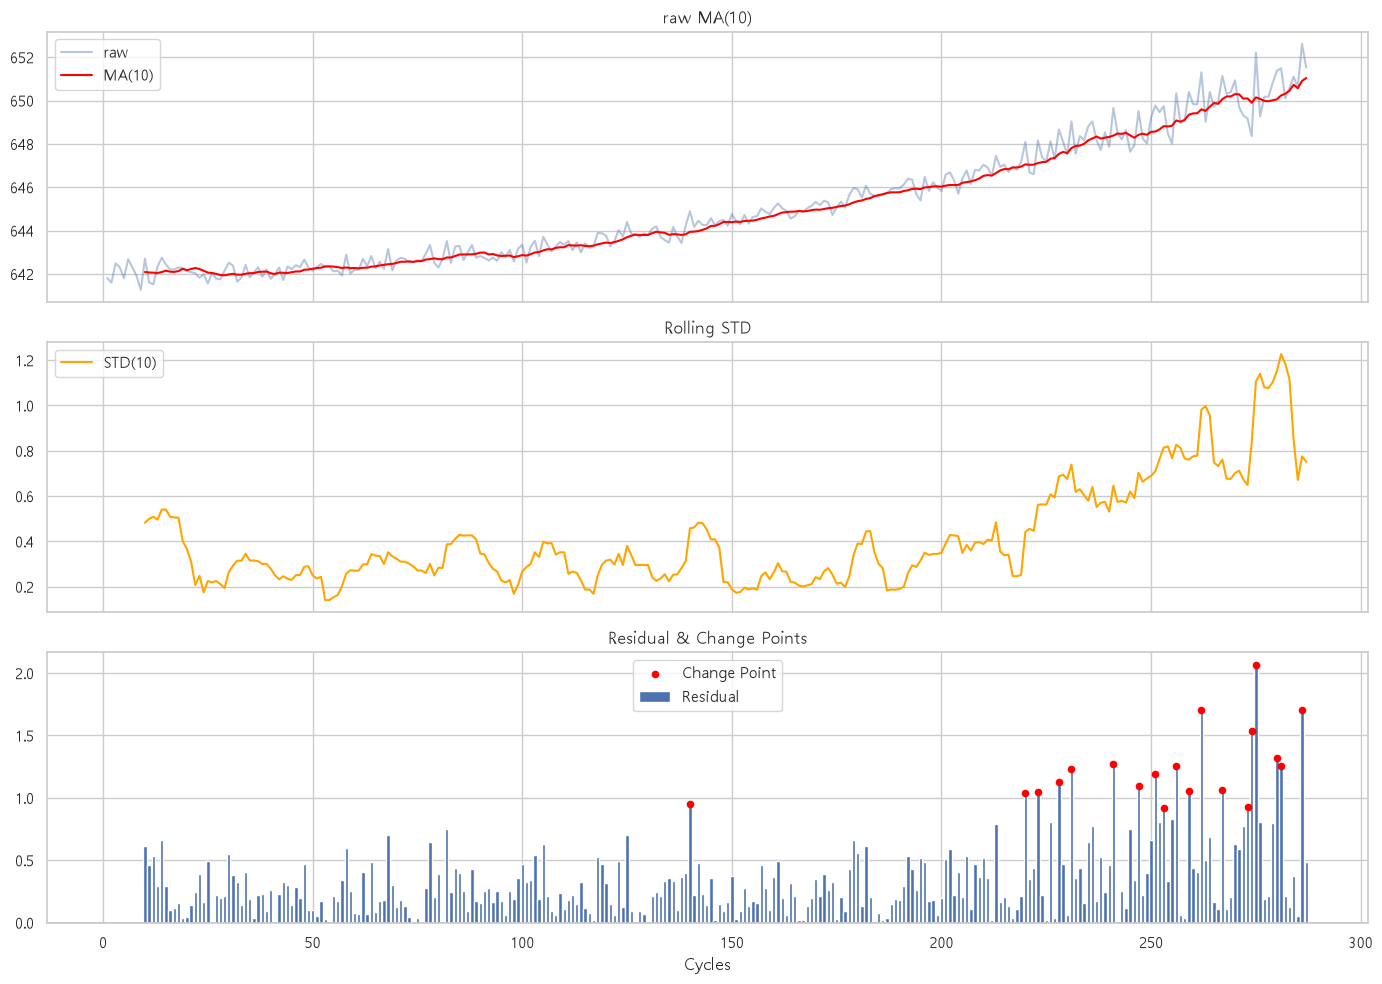

In [ ]:
fig, (ax1, ax2, ax3) = plt.subplots(
    3, 1,
    figsize=(14, 10),
    sharex=True
)


chg_data = u2[u2['chg'] == True]


# 1. 원본 이동평균
ax1.plot(
    u2['time_cycles'],
      s,
        label='raw',
          alpha=0.4
          )

ax1.plot(
    u2['time_cycles'],
      u2['ma'],
        label='MA(10)',
          color='red'
          )

ax1.set_title('raw MA(10)')
ax1.legend()

# ax1.grid(alpha=0.3)

# 2. 이동 편차
ax2.plot(
    u2['time_cycles'],
      u2['std'],
        color='orange',
          label='STD(10)'
          )

ax2.set_title('Rolling STD' )
ax2.legend()

# ax2.grid(alpha=0.3)

# 3. 잔차 + 변화점


ax3.bar(
    u2['time_cycles'],
      resid.abs(),
        label='Residual'
        )



ax3.scatter(
    chg_data['time_cycles'],
    resid.abs().loc[chg_data.index],
    color='red',
    label='Point',
    s=20
)
# ax3.axhline(0, color='black', linewidth=1)

# ax3.

ax3.set_title('Residual & Change Points')

ax3.legend()

# ax3.grid(alpha=0.3)

# 전체 X축 이름
ax3.set_xlabel('Cycles')

plt.tight_layout()

plt.show()